# Group Project

In [32]:
# Import libraries
import pandas as pd
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt

In [33]:
#import BankGP.xlsx
df = pd.read_excel("BankGP.xlsx")

# Display the first 10 rows
df.head(20)


,Loan Amount,Loan Duration,Interest Rate,Credit Score,Loan Type,Repayment Status,Monthly Payment Amount,Age,Income,Average_balance,Employment_type,Seniority,Approval_Rate,Credit_approval
0,14797.948146,291.0,5.0,512.251074,Mortgage,Ongoing,574.428168,38.0,44108.0,3115.747392,Contract,5.0,0,0
1,12962.627609,94.0,3.0,795.102806,Auto,Ongoing,627.626284,31.0,8401.0,2006.180587,Permanent,2.0,0,0
2,72668.466035,272.0,7.0,718.526915,Personal,Paid Off,781.125473,28.0,7460.0,225.959050,Contract,12.0,0,0
3,27653.452184,17.0,4.0,565.717364,Auto,Paid Off,448.815675,47.0,21040.0,2110.999812,Self-employed,16.0,0,0
4,81380.064046,74.0,3.0,723.318143,Auto,Ongoing,332.796039,31.0,65475.0,1498.552585,Permanent,9.0,0,0
5,57121.079218,48.0,6.0,NaN,Mortgage,Ongoing,920.045089,51.0,72611.0,348.392677,Contract,7.0,0,0
6,77130.357119,189.0,4.0,554.986149,Personal,Ongoing,574.574806,55.0,59626.0,4395.204998,Contract,2.0,0,0
7,36394.620959,144.0,7.0,686.255545,Auto,Ongoing,310.782775,39.0,9558.0,2549.190844,Permanent,14.0,0,0
8,55132.070514,150.0,2.0,706.473918,Personal,Paid Off,270.968843,22.0,24815.0,1029.150970,Permanent,NaN,0,0
9,68332.891141,91.0,4.0,651.023070,Auto,Ongoing,606.157643,30.0,64238.0,2094.690520,Self-employed,2.0,0,0


In [34]:
#Clean data
# Review bank.xlsx information 
df.shape

(200, 14)

In [35]:
# Review bank.xlsx columns 
df.columns

Index(['Loan Amount', 'Loan Duration', 'Interest Rate', 'Credit Score',
       'Loan Type', 'Repayment Status', 'Monthly Payment Amount', 'Age',
       'Income', 'Average_balance', 'Employment_type', 'Seniority',
       'Approval_Rate', 'Credit_approval'],
      dtype='str')

In [36]:
# Review data_f1 general information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan Amount             199 non-null    float64
 1   Loan Duration           198 non-null    float64
 2   Interest Rate           199 non-null    float64
 3   Credit Score            199 non-null    float64
 4   Loan Type               198 non-null    str    
 5   Repayment Status        199 non-null    str    
 6   Monthly Payment Amount  199 non-null    float64
 7   Age                     199 non-null    float64
 8   Income                  199 non-null    float64
 9   Average_balance         199 non-null    float64
 10  Employment_type         199 non-null    str    
 11  Seniority               199 non-null    float64
 12  Approval_Rate           200 non-null    int64  
 13  Credit_approval         200 non-null    int64  
dtypes: float64(9), int64(2), str(3)
memory usage: 26.7 KB

In [37]:
# How many rows have missing information in each columns
df.isna().sum()

Loan Amount               1
Loan Duration             2
Interest Rate             1
Credit Score              1
Loan Type                 2
Repayment Status          1
Monthly Payment Amount    1
Age                       1
Income                    1
Average_balance           1
Employment_type           1
Seniority                 1
Approval_Rate             0
Credit_approval           0
dtype: int64

In [38]:
# Drop unneccesary rows
df = df.drop(columns = "Seniority")

In [39]:
# Replace text representations of missing values with actual NaN
df = df.replace(["NaN", "nan", "None", ""], np.nan)

# Fill missing numerical values with median
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
categorical_cols = df.select_dtypes(include=["object", "str", "category"]).columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check remaining missing values
print(df.isna().sum())


Loan Amount               0
Loan Duration             0
Interest Rate             0
Credit Score              0
Loan Type                 0
Repayment Status          0
Monthly Payment Amount    0
Age                       0
Income                    0
Average_balance           0
Employment_type           0
Approval_Rate             0
Credit_approval           0
dtype: int64


In [40]:
# Check after cleaning the first 20 rows
df.head(20)

,Loan Amount,Loan Duration,Interest Rate,Credit Score,Loan Type,Repayment Status,Monthly Payment Amount,Age,Income,Average_balance,Employment_type,Approval_Rate,Credit_approval
0,14797.948146,291.0,5.0,512.251074,Mortgage,Ongoing,574.428168,38.0,44108.0,3115.747392,Contract,0,0
1,12962.627609,94.0,3.0,795.102806,Auto,Ongoing,627.626284,31.0,8401.0,2006.180587,Permanent,0,0
2,72668.466035,272.0,7.0,718.526915,Personal,Paid Off,781.125473,28.0,7460.0,225.959050,Contract,0,0
3,27653.452184,17.0,4.0,565.717364,Auto,Paid Off,448.815675,47.0,21040.0,2110.999812,Self-employed,0,0
4,81380.064046,74.0,3.0,723.318143,Auto,Ongoing,332.796039,31.0,65475.0,1498.552585,Permanent,0,0
5,57121.079218,48.0,6.0,655.971942,Mortgage,Ongoing,920.045089,51.0,72611.0,348.392677,Contract,0,0
6,77130.357119,189.0,4.0,554.986149,Personal,Ongoing,574.574806,55.0,59626.0,4395.204998,Contract,0,0
7,36394.620959,144.0,7.0,686.255545,Auto,Ongoing,310.782775,39.0,9558.0,2549.190844,Permanent,0,0
8,55132.070514,150.0,2.0,706.473918,Personal,Paid Off,270.968843,22.0,24815.0,1029.150970,Permanent,0,0
9,68332.891141,91.0,4.0,651.023070,Auto,Ongoing,606.157643,30.0,64238.0,2094.690520,Self-employed,0,0


In [41]:
# Review the data and how many rows have missing information in each columns
df.isna().sum()

Loan Amount               0
Loan Duration             0
Interest Rate             0
Credit Score              0
Loan Type                 0
Repayment Status          0
Monthly Payment Amount    0
Age                       0
Income                    0
Average_balance           0
Employment_type           0
Approval_Rate             0
Credit_approval           0
dtype: int64

In [42]:
# Target variable
y = df["Credit_approval"]

# Features used for prediction
X = df.drop(columns=[
    "Credit_approval",
    "Approval_Rate",
    "Repayment Status"
])

print("Features:", X.columns.tolist())
print("Target distribution:")
print(y.value_counts())

Features: ['Loan Amount', 'Loan Duration', 'Interest Rate', 'Credit Score', 'Loan Type', 'Monthly Payment Amount', 'Age', 'Income', 'Average_balance', 'Employment_type']
Target distribution:
Credit_approval
0    100
1    100
Name: count, dtype: int64


In [43]:
# split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 160
Testing observations: 40


In [44]:
# prepare the data for machine learning
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

In [45]:
#train two classification models
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!



 Logistic Regression
              precision    recall  f1-score   support

           0       0.95      0.90      0.92        20
           1       0.90      0.95      0.93        20

    accuracy                           0.93        40
   macro avg       0.93      0.93      0.92        40
weighted avg       0.93      0.93      0.92        40



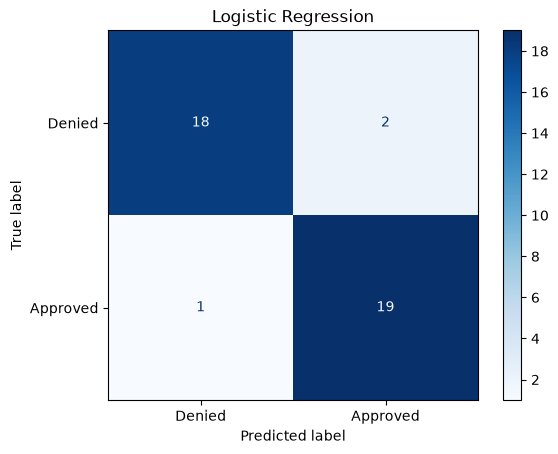


 Random Forest
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        20
           1       0.90      0.90      0.90        20

    accuracy                           0.90        40
   macro avg       0.90      0.90      0.90        40
weighted avg       0.90      0.90      0.90        40



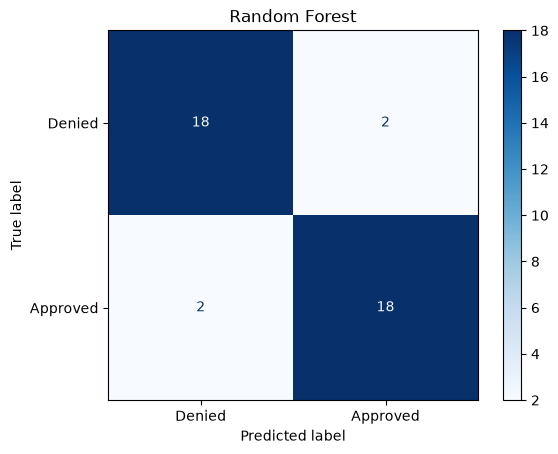

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.925,0.904762,0.95,0.926829
1,Random Forest,0.900,0.900000,0.90,0.900000


In [46]:
#evaluate model performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

    print("\n", name)
    print(classification_report(y_test, y_pred))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["Denied", "Approved"],
        cmap="Blues"
    )
    plt.title(name)
    plt.show()

results_df = pd.DataFrame(results)
display(results_df)

### Model Evaluation and Results

The objective of this project was to predict credit approval or denial using machine learning classification techniques. Two models were developed: Logistic Regression and Random Forest.

The dataset consisted of 200 credit applications, with 100 approved and 100 denied applications. The data was divided into 80% training observations (160 applications) and 20% testing observations (40 applications).

**Logistic Regression achieved an accuracy of 92.5%, while Random Forest achieved 90%.** This means Logistic Regression correctly classified 37 out of 40 applications, compared with 36 correct classifications for Random Forest.

Logistic Regression also achieved a precision of 90.48%, recall of 95%, and F1 score of 92.68% for approved applications. These results indicate that the model was effective at identifying approved applications while maintaining relatively few incorrect predictions.

The confusion matrix showed that Logistic Regression correctly classified 19 approved applications and 18 denied applications. It incorrectly classified two denied applications as approved and one approved application as denied.

Random Forest correctly classified 18 approved and 18 denied applications, with four incorrect predictions.

**Conclusion**

Based on the initial test results, Logistic Regression was the better-performing model for predicting credit approval or denial. However, because the dataset was relatively small, additional validation would be necessary to establish whether this performance generalizes to new applications.

These findings suggest that machine learning can be useful for supporting credit decision analysis, although model predictions should not be treated as definitive lending decisions.